In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, classification_report, confusion_matrix, 
    ConfusionMatrixDisplay
)
import joblib
import sys
import time
from inference_utils import preprocess_and_select_25

In [2]:
PROJECT_DIR = Path(r"E:\DataMining_Group32")
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.append(str(NOTEBOOKS_DIR))

RAW_SPLIT_DIR = PROJECT_DIR / "data" / "raw_split"
MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

print("="*60)
print("LOADING RAW TEST DATA (No SMOTE, No Data Leakage)")
print("="*60)

X_test_raw = pd.read_csv(RAW_SPLIT_DIR / "X_test_before.csv")
y_test = pd.read_csv(RAW_SPLIT_DIR / "y_test.csv").squeeze("columns")

print("Applying Preprocessing Pipeline & Selecting Top 25 Features...")
X_test_processed = preprocess_and_select_25(X_test_raw, PROJECT_DIR)

print(f"Final Test Set Shape for Evaluation: {X_test_processed.shape}")

print("Loading the 3 trained models...")
lr_model = joblib.load(MODELS_DIR / "logistic_regression_model.pkl")
dt_model = joblib.load(MODELS_DIR / "decision_tree_model.pkl")
xgb_model = joblib.load(MODELS_DIR / "xgboost_model.pkl")

def predict_lr_with_thresholds(model, X):
    proba = model.predict_proba(X)
    model_classes = model.named_steps["lr"].classes_
    classes = np.array([1, 2, 3, 4])
    class_indices = [list(model_classes).index(c) for c in classes]
    proba = proba[:, class_indices]
    multipliers = np.array([5.0, 0.8, 1.5, 10.0]) 
    return classes[np.argmax(proba * multipliers, axis=1)]
print("Making predictions on Test Set...")
start_lr = time.time()
y_pred_lr = predict_lr_with_thresholds(lr_model, X_test_processed)
time_lr = time.time() - start_lr

start_dt = time.time()
y_pred_dt = dt_model.predict(X_test_processed)
time_dt = time.time() - start_dt

start_xgb = time.time()
y_pred_xgb = xgb_model.predict(X_test_processed) + 1 
time_xgb = time.time() - start_xgb

def get_metrics(y_true, y_pred, time_taken):
    return {
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro"), 4),
        "Weighted F1": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "Inference Time (s)": round(time_taken, 4)
    }

metrics_lr = get_metrics(y_test, y_pred_lr, time_lr)
metrics_dt = get_metrics(y_test, y_pred_dt, time_dt)
metrics_xgb = get_metrics(y_test, y_pred_xgb, time_xgb)

# ۶. ایجاد جدول مقایسه‌ای نهایی
comparison_df = pd.DataFrame(
    [metrics_lr, metrics_dt, metrics_xgb],
    index=["Logistic Regression (Tuned Threshold)", "Decision Tree (SMOTE+Tuned)", "XGBoost (SMOTE+Tuned)"]
)

print("\n" + "="*70)
print(" FINAL MODEL COMPARISON ON TEST SET")
print("="*70)
display(comparison_df)

LOADING RAW TEST DATA (No SMOTE, No Data Leakage)
Applying Preprocessing Pipeline & Selecting Top 25 Features...
Final Test Set Shape for Evaluation: (15000, 25)
Loading the 3 trained models...
Making predictions on Test Set...

 FINAL MODEL COMPARISON ON TEST SET


,Accuracy,Macro F1,Weighted F1,Inference Time (s)
Logistic Regression (Tuned Threshold),0.7721,0.4783,0.8006,0.0214
Decision Tree (SMOTE+Tuned),0.8082,0.4910,0.8161,0.0140
XGBoost (SMOTE+Tuned),0.8437,0.5772,0.8509,0.2063


In [3]:
final_model_name = "XGBoost (SMOTE+Tuned)"
print(f"\n[DECISION] The final model is: {final_model_name}")

print("\n" + "="*70)
print(f" DETAILED EVALUATION FOR FINAL MODEL: {final_model_name}")
print("="*70)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_xgb, zero_division=0))


[DECISION] The final model is: XGBoost (SMOTE+Tuned)

 DETAILED EVALUATION FOR FINAL MODEL: XGBoost (SMOTE+Tuned)

--- Classification Report ---
              precision    recall  f1-score   support

           1       0.33      0.44      0.38       127
           2       0.94      0.87      0.90     11947
           3       0.62      0.83      0.71      2519
           4       0.30      0.33      0.31       407

    accuracy                           0.84     15000
   macro avg       0.55      0.62      0.58     15000
weighted avg       0.87      0.84      0.85     15000



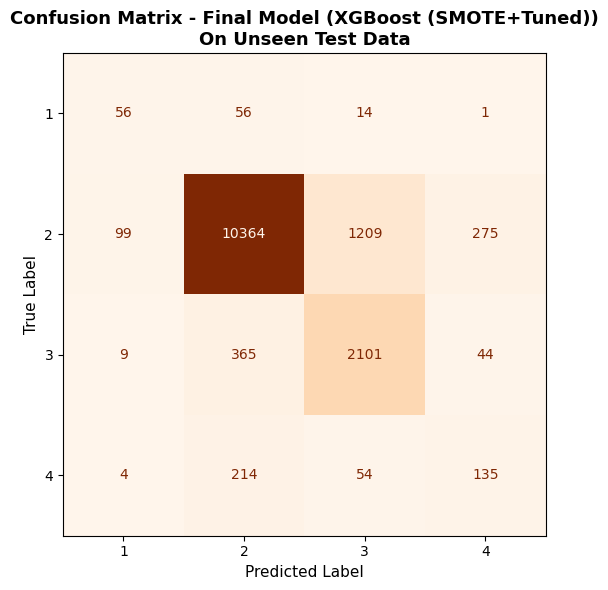

Evaluation complete and plot saved.


In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred_xgb, labels=[1, 2, 3, 4])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3, 4])
disp.plot(cmap='Oranges', ax=ax, values_format='d', colorbar=False)
ax.set_title(f"Confusion Matrix - Final Model ({final_model_name})\nOn Unseen Test Data", fontsize=13, fontweight='bold')
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "final_model_confusion_matrix.png", dpi=300)
plt.show()

print("Evaluation complete and plot saved.")